# Análise dos resultados da simulação de drones

Este notebook compara as simulações **Estático** e **Dinâmico** com gráficos simples de MMT por entrega, frota total e por etapa, tamanho da fila e delay. Também resume o SLA e as médias para comparação rápida.

**Semântica importante:** o campo `MeanMissionTime` de `ad_mmt_log*.csv` contém a duração de cada missão entregue, não uma média móvel. A média, mediana e P95 são calculados sobre essas entregas. O campo `MMT` do arquivo de estados é uma métrica separada amostrada pelo scheduler e pode estar zerada.

O tempo de missão é calculado para cada entrega. O SLA indica a porcentagem de entregas concluídas em até 80 minutos. Os rótulos identificam os arquivos configurados abaixo.

In [ ]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o notebook com a pasta do projeto como diretório de trabalho.
PASTA = Path.cwd()
PASTA_GRAFICOS = PASTA / 'graficos_comparacao'
PASTA_GRAFICOS.mkdir(parents=True, exist_ok=True)

# Edite os nomes/rótulos depois de verificar o config.properties de cada execução.
ARQUIVOS = {
    'Estático': {
        'ad_mmt': PASTA / 'ad_mmt_log.csv',
        'state': PASTA / 'system_state_log.csv',
    },
    'Dinâmico': {
        'ad_mmt': PASTA / 'ad_mmt_log_dynamic_run.csv',
        'state': PASTA / 'system_state_log_dynamic_run.csv',
    },
}

# Inclua aqui pares (rótulo_a, rótulo_b) somente se forem comparáveis
# (mesmo cenário, duração, parâmetros e protocolo experimental).
COMPARACOES_VALIDAS = []

SLA_MMT_MIN = 80
JANELA_MOVEL_ENTREGAS = 50
FROTA_REFERENCIA = None  # Ex.: 80; deixa None até definir uma referência útil.

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 9,
    'figure.figsize': (11, 6),
})

print(f'Pasta de entrada: {PASTA.resolve()}')
print(f'Pasta de gráficos: {PASTA_GRAFICOS.resolve()}')


Pasta de entrada: /home/callmepeh/Downloads/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3
Pasta de gráficos: /home/callmepeh/Downloads/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3/graficos_comparacao


In [ ]:
COLUNAS_MISSAO = ['Time(ms)', 'CurrentAD', 'MeanMissionTime']
COLUNAS_ESTADO = [
    'Time(ms)', 'TotalDrones', 'OperationalDrones', 'ActiveDrones',
    'IdleDrones', 'RechargeDrones', 'QueueSize', 'MMT', 'Throughput',
    'TargetMMT', 'RecommendedFleet',
]

def ler_csv_validado(caminho, colunas_obrigatorias, rotulo):
    caminho = Path(caminho)
    if not caminho.is_file():
        raise FileNotFoundError(f'{rotulo}: arquivo não encontrado: {caminho}')
    df = pd.read_csv(caminho, sep=';', decimal='.')
    df.columns = df.columns.astype(str).str.strip()
    ausentes = [col for col in colunas_obrigatorias if col not in df.columns]
    if ausentes:
        raise ValueError(f'{rotulo}: colunas obrigatórias ausentes em {caminho.name}: {ausentes}')
    if df.empty:
        raise ValueError(f'{rotulo}: CSV sem linhas de dados: {caminho.name}')
    for col in colunas_obrigatorias:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    invalidas = df[colunas_obrigatorias].isna().any(axis=1)
    if invalidas.any():
        warnings.warn(f'{rotulo}: descartando {int(invalidas.sum())} linha(s) com campos numéricos ausentes/inválidos em {caminho.name}.')
        df = df.loc[~invalidas].copy()
    if df.empty:
        raise ValueError(f'{rotulo}: nenhuma linha válida restou em {caminho.name}')
    df = df.sort_values('Time(ms)', kind='stable').reset_index(drop=True)
    return df

dados = {}
arquivos_ausentes = []
for nome, caminhos in ARQUIVOS.items():
    faltando = [str(Path(p)) for p in caminhos.values() if not Path(p).is_file()]
    if faltando:
        arquivos_ausentes.extend(f'{nome}: {p}' for p in faltando)
        continue
    df_missao = ler_csv_validado(caminhos['ad_mmt'], COLUNAS_MISSAO, f'{nome}/missões')
    df_estado = ler_csv_validado(caminhos['state'], COLUNAS_ESTADO, f'{nome}/estados')
    df_missao['Time(min)'] = df_missao['Time(ms)'] / 60_000
    df_missao['AD(min)'] = df_missao['CurrentAD'] / 60_000
    df_missao['MissionTime(min)'] = df_missao['MeanMissionTime'] / 60_000
    df_missao['MissionRollingMean(min)'] = df_missao['MissionTime(min)'].rolling(
        JANELA_MOVEL_ENTREGAS, min_periods=1
    ).mean()
    df_missao['DeliveryNumber'] = np.arange(1, len(df_missao) + 1)
    df_estado['Time(min)'] = df_estado['Time(ms)'] / 60_000
    for origem, destino in [('AD', 'AD(min)'), ('MMT', 'StateMMT(min)'), ('TargetMMT', 'TargetMMT(min)')]:
        if origem in df_estado.columns:
            df_estado[destino] = df_estado[origem] / 60_000
    if (df_estado['Time(ms)'].diff().dropna() < 0).any():
        raise ValueError(f'{nome}: tempo de estado não está ordenado crescentemente')
    dados[nome] = {'mission': df_missao, 'state': df_estado}

if arquivos_ausentes:
    print('Arquivos configurados, mas ausentes (esses casos serão ignorados):')
    for item in arquivos_ausentes:
        print(f'  - {item}')
if not dados:
    raise FileNotFoundError('Nenhum par completo de CSV foi encontrado. Ajuste ARQUIVOS na célula de configuração.')

print('\nCasos carregados:')
for nome, item in dados.items():
    print(f"  {nome}: {len(item['mission']):,} entregas, {len(item['state']):,} amostras de estado")



Casos carregados:
  Estático: 1,357 entregas, 240 amostras de estado
  Dinâmico: 1,354 entregas, 240 amostras de estado


In [ ]:
def media_temporal(df, coluna):
    """Média ponderada pelo tempo entre snapshots, incluindo a última duração estimada."""
    valores = pd.to_numeric(df[coluna], errors='coerce')
    tempos = pd.to_numeric(df['Time(ms)'], errors='coerce')
    validos = valores.notna() & tempos.notna()
    valores, tempos = valores[validos], tempos[validos]
    if len(valores) == 0:
        return np.nan
    if len(valores) == 1:
        return float(valores.iloc[0])
    duracoes = tempos.shift(-1) - tempos
    intervalos = duracoes.iloc[:-1]
    intervalos_validos = intervalos[intervalos > 0]
    duracao_final = float(intervalos_validos.median()) if not intervalos_validos.empty else 0.0
    duracoes.iloc[-1] = duracao_final
    duracoes = duracoes.clip(lower=0)
    if duracoes.sum() <= 0:
        return float(valores.mean())
    return float(np.average(valores, weights=duracoes))

resultados = []
for nome, item in dados.items():
    missao, estado = item['mission'], item['state']
    tempos = missao['MissionTime(min)'].dropna()
    dentro_sla = tempos <= SLA_MMT_MIN
    frota_media_tempo = media_temporal(estado, 'TotalDrones')
    ativos_media_tempo = media_temporal(estado, 'ActiveDrones')
    fila = estado['QueueSize'].dropna()
    throughput = estado['Throughput'].dropna()
    frota = estado['TotalDrones'].dropna()
    resultado = {
        'Configuração': nome,
        'Entregas analisadas': int(tempos.count()),
        'MMT médio por entrega (min)': float(tempos.mean()) if len(tempos) else np.nan,
        'MMT mediano por entrega (min)': float(tempos.median()) if len(tempos) else np.nan,
        'MMT P95 por entrega (min)': float(tempos.quantile(.95)) if len(tempos) else np.nan,
        'MMT máximo por entrega (min)': float(tempos.max()) if len(tempos) else np.nan,
        'SLA atendido por entrega (%)': float(dentro_sla.mean() * 100) if len(tempos) else np.nan,
        'Violações SLA': int((~dentro_sla).sum()),
        'Amostras fora SLA (%)': float((~dentro_sla).mean() * 100) if len(tempos) else np.nan,
        'Fila média por snapshot': float(fila.mean()) if len(fila) else np.nan,
        'Fila máxima': float(fila.max()) if len(fila) else np.nan,
        'Throughput médio por snapshot': float(throughput.mean()) if len(throughput) else np.nan,
        'Frota média ponderada no tempo': frota_media_tempo,
        'Frota mínima observada': float(frota.min()) if len(frota) else np.nan,
        'Frota máxima observada': float(frota.max()) if len(frota) else np.nan,
        'Ativos médios ponderados no tempo': ativos_media_tempo,
        'Ociosos médios ponderados no tempo': media_temporal(estado, 'IdleDrones'),
        'Em recarga médios ponderados no tempo': media_temporal(estado, 'RechargeDrones'),
        'Utilização média ponderada (%)': (ativos_media_tempo / frota_media_tempo * 100)
            if pd.notna(ativos_media_tempo) and pd.notna(frota_media_tempo) and frota_media_tempo > 0 else np.nan,
        'Frota recomendada média por snapshot': float(estado['RecommendedFleet'].mean())
            if 'RecommendedFleet' in estado and estado['RecommendedFleet'].notna().any() else np.nan,
        'Estado MMT médio (min)': float(estado['StateMMT(min)'].mean())
            if 'StateMMT(min)' in estado and estado['StateMMT(min)'].notna().any() else np.nan,
    }
    if FROTA_REFERENCIA is not None:
        resultado[f'Tempo abaixo de {FROTA_REFERENCIA} drones (%)'] = float((estado['TotalDrones'] < FROTA_REFERENCIA).mean() * 100)
        resultado[f'Tempo até {FROTA_REFERENCIA} drones (%)'] = float((estado['TotalDrones'] <= FROTA_REFERENCIA).mean() * 100)
    resultados.append(resultado)

df_resultados = pd.DataFrame(resultados)
df_resultados.to_csv(PASTA_GRAFICOS / 'resumo_comparacao.csv', sep=';', decimal=',', index=False)
display(df_resultados.round(2))


,Configuração,Entregas analisadas,MMT médio por entrega (min),MMT mediano por entrega (min),MMT P95 por entrega (min),MMT máximo por entrega (min),SLA atendido por entrega (%),Violações SLA,Amostras fora SLA (%),Fila média por snapshot,...,Throughput médio por snapshot,Frota média ponderada no tempo,Frota mínima observada,Frota máxima observada,Ativos médios ponderados no tempo,Ociosos médios ponderados no tempo,Em recarga médios ponderados no tempo,Utilização média ponderada (%),Frota recomendada média por snapshot,Estado MMT médio (min)
0,Estático,1357,64.15,60.42,130.66,225.19,69.12,419,30.88,25.10,...,1.13,60.0,60.0,60.0,48.77,10.96,0.27,81.28,60.0,0.0
1,Dinâmico,1354,61.70,57.29,125.94,303.72,73.71,356,26.29,24.08,...,1.13,60.0,60.0,60.0,46.92,12.80,0.28,78.19,60.0,0.0


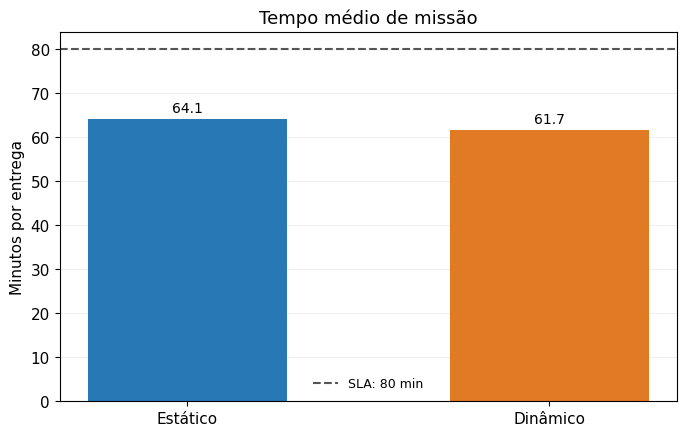

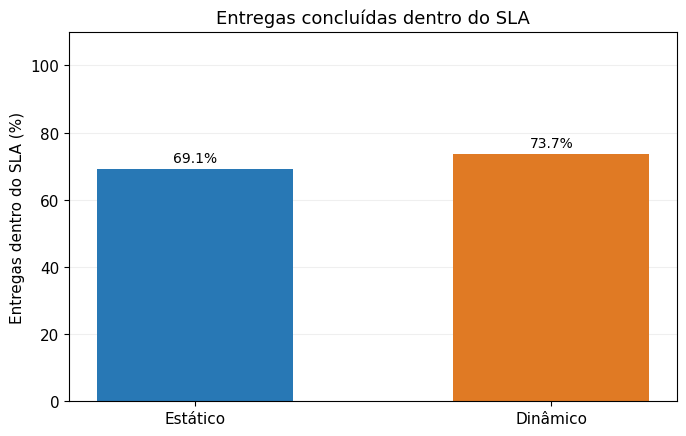

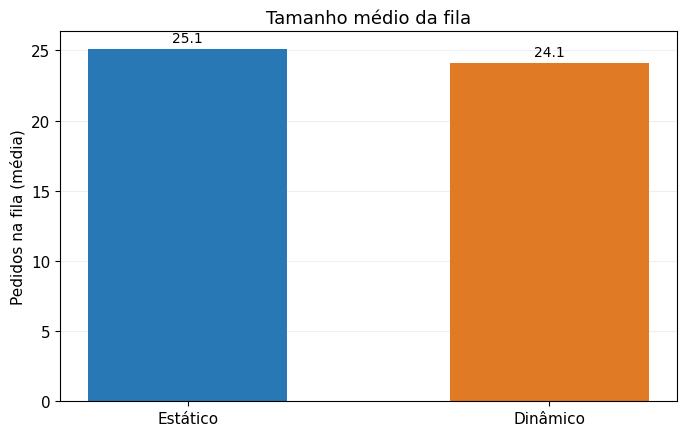

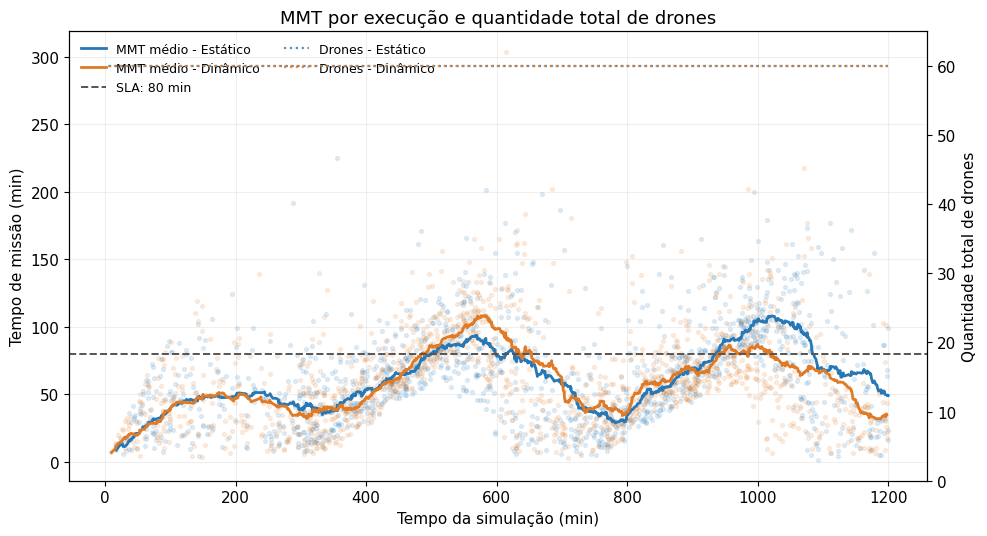

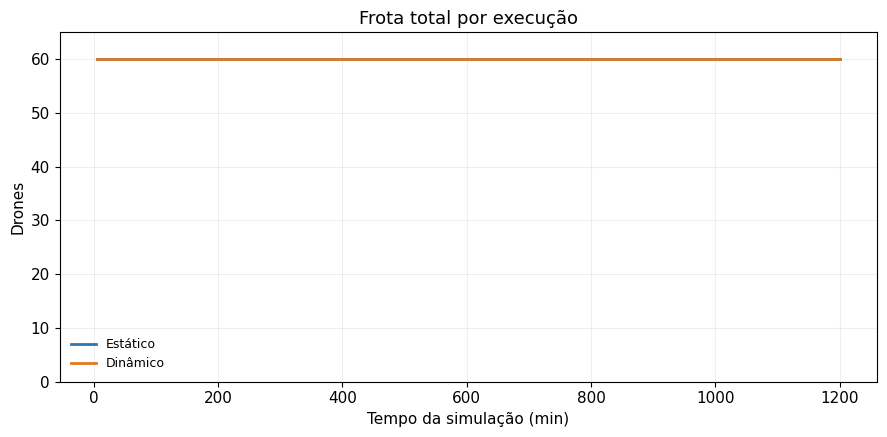

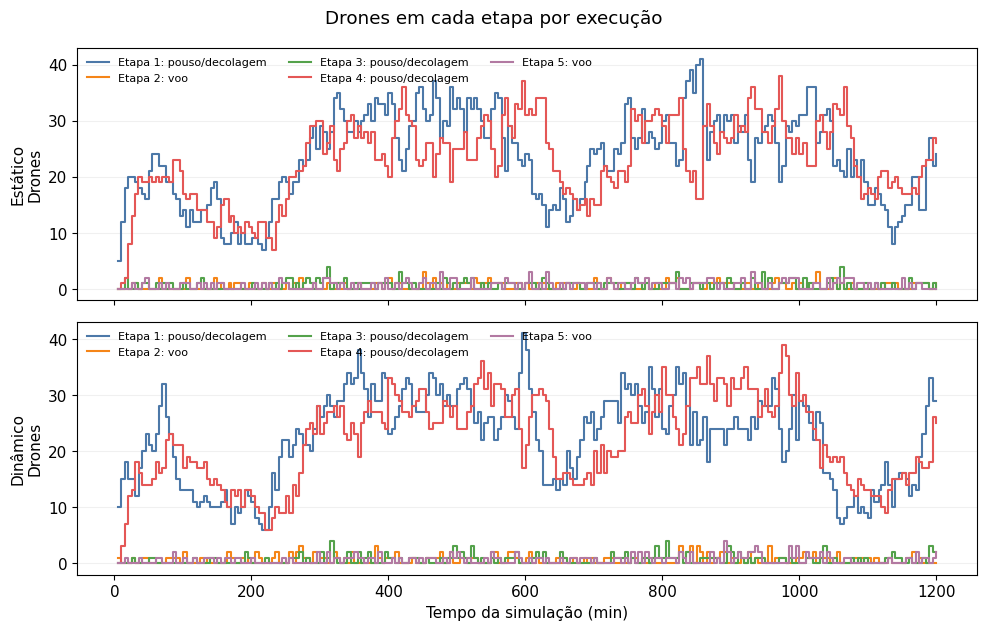

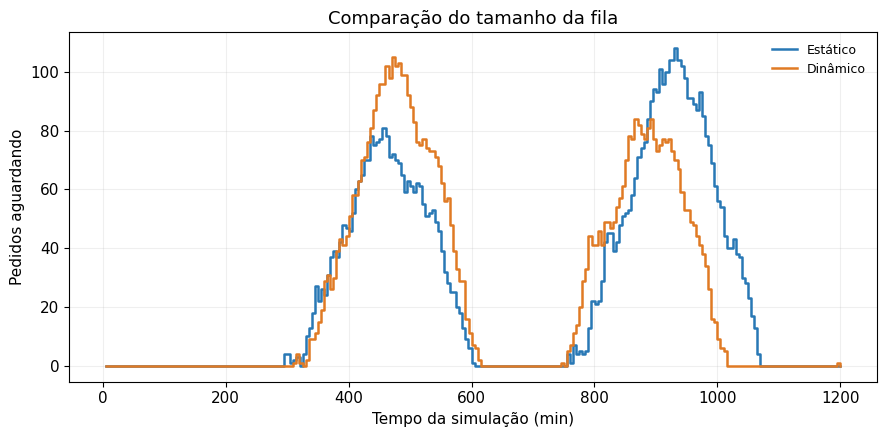

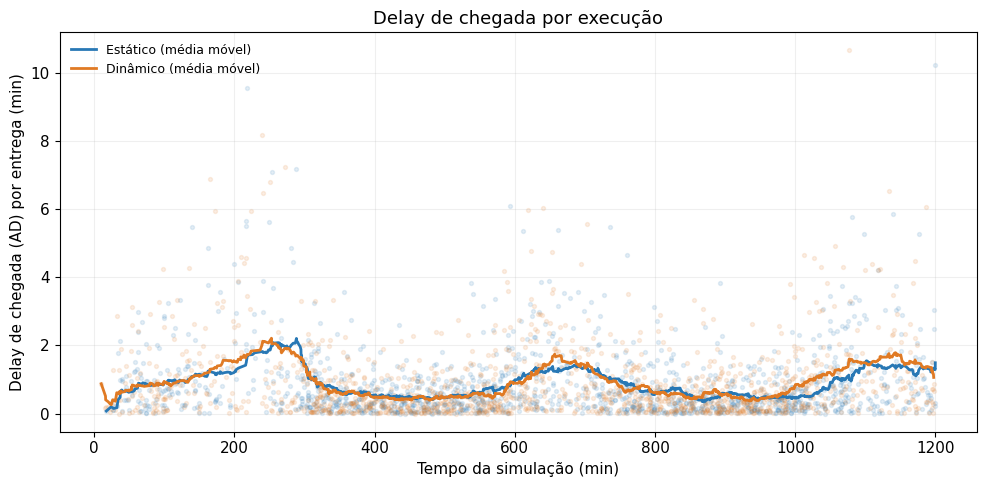

Gráficos e resumo salvos em: /home/callmepeh/Downloads/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3/graficos_comparacao


In [ ]:
def salvar(fig, nome):
    fig.tight_layout()
    fig.savefig(PASTA_GRAFICOS / nome, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

cores = {'Estático': '#2878B5', 'Dinâmico': '#E07A24'}
cores_etapas = ['#4C78A8', '#F58518', '#54A24B', '#E45756', '#B279A2']
CORE_OCIOSO = '#B8C2CC'  # cinza claro: drones ociosos (fora das etapas da missão)
CORE_RECARGA = '#72B7B2'  # turquesa: drones em recarga

def grafico_barras(coluna, titulo, eixo_y, arquivo, limite=None, linha_referencia=None, formato='{:.1f}'):
    valores = df_resultados.set_index('Configuração')[coluna].dropna()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    barras = ax.bar(valores.index, valores.values, color=[cores.get(nome, '#777777') for nome in valores.index], width=0.55)
    ax.set(title=titulo, ylabel=eixo_y)
    if limite is not None:
        ax.set_ylim(limite)
    if linha_referencia is not None:
        ax.axhline(linha_referencia, color='#555555', linestyle='--', linewidth=1.5, label=f'SLA: {linha_referencia} min')
        ax.legend(frameon=False)
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
    for barra, valor in zip(barras, valores.values):
        ax.annotate(formato.format(valor), (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                    xytext=(0, 5), textcoords='offset points', ha='center', fontsize=10)
    salvar(fig, arquivo)

grafico_barras('MMT médio por entrega (min)', 'Tempo médio de missão', 'Minutos por entrega',
               '01_tempo_medio_missao.png', linha_referencia=SLA_MMT_MIN)
grafico_barras('SLA atendido por entrega (%)', 'Entregas concluídas dentro do SLA', 'Entregas dentro do SLA (%)',
               '02_entregas_dentro_sla.png', limite=(0, 110), formato='{:.1f}%')
grafico_barras('Fila média por snapshot', 'Tamanho médio da fila', 'Pedidos na fila (média)',
               '03_fila_media.png', formato='{:.1f}')

# MMT por entrega: pontos individuais e média móvel, com a frota total no eixo direito.
fig, ax = plt.subplots(figsize=(10, 5.5))
ax_frota = ax.twinx()
for nome, item in dados.items():
    missoes, estado = item['mission'], item['state']
    cor = cores.get(nome, '#777777')
    ax.scatter(missoes['Time(min)'], missoes['MissionTime(min)'], s=8, alpha=.12, color=cor)
    ax.plot(missoes['Time(min)'], missoes['MissionRollingMean(min)'], color=cor, linewidth=2, label=f'MMT médio - {nome}')
    ax_frota.step(estado['Time(min)'], estado['TotalDrones'], where='post', color=cor,
                  linestyle=':', linewidth=1.6, alpha=.8, label=f'Drones - {nome}')
ax.axhline(SLA_MMT_MIN, color='#555555', linestyle='--', linewidth=1.4, label=f'SLA: {SLA_MMT_MIN} min')
ax.set(xlabel='Tempo da simulação (min)', ylabel='Tempo de missão (min)', title='MMT por execução e quantidade total de drones')
ax_frota.set_ylabel('Quantidade total de drones')
ax_frota.set_ylim(0, max(estado['TotalDrones'].max() for estado in [item['state'] for item in dados.values()]) + 5)
ax.grid(alpha=.2)
linhas = ax.get_lines() + ax_frota.get_lines()
ax.legend(linhas, [linha.get_label() for linha in linhas], loc='upper left', ncol=2, frameon=False)
salvar(fig, '04_mmt_por_execucao_e_frota.png')

# Quantidade total de drones ao longo da simulação.
fig, ax = plt.subplots(figsize=(9, 4.5))
for nome, item in dados.items():
    estado = item['state']
    ax.step(estado['Time(min)'], estado['TotalDrones'], where='post', color=cores.get(nome, '#777777'), label=nome, linewidth=2)
ax.set(xlabel='Tempo da simulação (min)', ylabel='Drones', title='Frota total por execução')
ax.set_ylim(0, max(estado['TotalDrones'].max() for estado in [item['state'] for item in dados.values()]) + 5)
ax.grid(alpha=.2)
ax.legend(frameon=False)
salvar(fig, '05_frota_total.png')

# Separar as etapas por tipo de atividade facilita a comparação dos estados.
etapas = [
    ('A', 'Etapa 1: pouso/decolagem'), ('B', 'Etapa 2: voo'),
    ('C', 'Etapa 3: pouso/decolagem'), ('D', 'Etapa 4: pouso/decolagem'), ('E', 'Etapa 5: voo'),
]
grupo_etapas = [
    ('voo', [etapas[1], etapas[4]], 'Drones nas etapas de voo', '06a_drones_etapas_voo.png'),
    ('pouso_decolagem', [etapas[0], etapas[2], etapas[3]],
     'Drones nas etapas de pouso/decolagem', '06b_drones_etapas_pouso_decolagem.png'),
]
ROTULO_ETAPA = {coluna: rotulo for coluna, rotulo in etapas}

def serie_passo(tempo, valores):
    """Converte uma série de snapshots em pontos (x, y) com degraus where=post."""
    x = np.asarray(tempo, dtype=float)
    y = np.asarray(valores, dtype=float)
    if len(x) == 0:
        return x, y
    return np.concatenate([x, [x[-1] * 1.02 + 1.0]]), np.concatenate([y, [y[-1]]])

def limites_grupo(etapas_grupo):
    """Escala comum (min, máx) entre as configurações, para comparar os subplots."""
    valores = [item['state'][coluna].dropna() for item in dados.values() for coluna, _ in etapas_grupo]
    maximo = max((serie.max() for serie in valores if len(serie)), default=0)
    minimo = min((serie.min() for serie in valores if len(serie)), default=0)
    maximo = float(maximo) if maximo > 0 else 1.0
    return (0, maximo * 1.18) if minimo >= 0 else (min(minimo, 0) * 1.18, maximo * 1.18)

for _, etapas_grupo, titulo, arquivo in grupo_etapas:
    fig, axes = plt.subplots(len(dados), 1, figsize=(12, max(5, 4.2 * len(dados))),
                             sharex=True, squeeze=False)
    limite_inferior, limite_superior = limites_grupo(etapas_grupo)
    for ax, (nome, item) in zip(axes[:, 0], dados.items()):
        estado = item['state']
        tempo = estado['Time(min)']
        for coluna, rotulo in etapas_grupo:
            cor = cores_etapas['ABCDE'.index(coluna)]
            valores = estado[coluna].fillna(0)
            # Área preenchida (volume de drones) com a linha sólida por cima, para leitura clara.
            x_passo, y_passo = serie_passo(tempo, valores)
            ax.fill_between(x_passo, y_passo, step='post', color=cor, alpha=.22, linewidth=0)
            ax.step(tempo, valores, where='post', color=cor, linewidth=2.2, label=rotulo, zorder=3)
        # Linha de referência: frota total da execução, para situar o quanto cada etapa usa da frota.
        if 'TotalDrones' in estado:
            x_frota, y_frota = serie_passo(tempo, estado['TotalDrones'].fillna(0))
            ax.step(x_frota, y_frota, where='post', color='#333333', linestyle='--',
                    linewidth=1.3, alpha=.65, label='Frota total', zorder=2)
        # Média da etapa, para mostrar o patamar típico sem depender do pico.
        for coluna, rotulo in etapas_grupo:
            cor = cores_etapas['ABCDE'.index(coluna)]
            media = estado[coluna].fillna(0).mean()
            ax.axhline(media, color=cor, linestyle=':', linewidth=1.2, alpha=.85)
            ax.annotate(f'média {rotulo.split(':')[0].strip()} = {media:.1f}',
                        xy=(0.998, media), xycoords=('axes fraction', 'data'),
                        xytext=(-4, 4), textcoords='offset points', ha='right',
                        fontsize=8.5, color=cor)
        ax.set_ylabel(f'{nome}\nDrones')
        ax.set_ylim(limite_inferior, limite_superior)
        ax.grid(axis='y', alpha=.3, linestyle='--')
        ax.set_axisbelow(True)
        ax.legend(loc='upper left', ncol=len(etapas_grupo) + 1, fontsize=9.5, frameon=True,
                  framealpha=.9, edgecolor='none')
    axes[-1, 0].set_xlabel('Tempo da simulação (min)')
    fig.suptitle(titulo, fontsize=15, fontweight='bold')
    salvar(fig, arquivo)

# Gráfico de estados dos drones (duplicado em duas versões):
# 1) um painel por configuração e 2) comparativo em porcentagem da frota.
def estados_da_frota(estado):
    """Series empilháveis com todos os estados dos drones de um snapshot."""
    series = {'Ociosos': estado.get('IdleDrones', 0), 'Em recarga': estado.get('RechargeDrones', 0)}
    for coluna, rotulo in etapas:
        series[rotulo] = estado[coluna] if coluna in estado else 0
    return {rotulo: pd.Series(valores, index=estado.index, dtype=float).fillna(0)
            for rotulo, valores in series.items()}

series_estados = [estados_da_frota(item['state']) for item in dados.values()]
rotulos_estados = list(series_estados[0].keys())
cores_estados = [CORE_OCIOSO, CORE_RECARGA] + cores_etapas

# Versão 1: um gráfico de áreas empilhadas por configuração, em drones absolutos.
fig, axes = plt.subplots(len(dados), 1, figsize=(12, max(5, 4.2 * len(dados))),
                         sharex=True, squeeze=False)
limite_frota = max(float(item['state']['TotalDrones'].max()) for item in dados.values())
for ax, ((nome, item), series) in zip(axes[:, 0], zip(dados.items(), series_estados)):
    tempo = item['state']['Time(min)']
    pilha = np.vstack([series[rotulo].to_numpy(dtype=float) for rotulo in rotulos_estados])
    x_passo, _ = serie_passo(tempo, item['state']['TotalDrones'])
    empilhado = np.vstack([np.concatenate([linha, [linha[-1]]]) for linha in pilha])
    ax.stackplot(x_passo, *empilhado, labels=rotulos_estados, colors=cores_estados,
                 edgecolor='white', linewidth=.6)
    ax.step(x_passo, np.concatenate([item['state']['TotalDrones'].to_numpy(dtype=float),
                                     [item['state']['TotalDrones'].iloc[-1]]]),
            where='post', color='#333333', linestyle='--', linewidth=1.3, alpha=.7)
    ax.set(title=nome, ylabel='Drones', xlim=(0, x_passo[-1]), ylim=(0, limite_frota * 1.08))
    ax.grid(axis='y', alpha=.3, linestyle='--')
    ax.set_axisbelow(True)
    ax.legend(loc='upper left', ncol=4, fontsize=9, frameon=True, framealpha=.9, edgecolor='none')
axes[-1, 0].set_xlabel('Tempo da simulação (min)')
fig.suptitle('Estados dos drones ao longo da simulação', fontsize=15, fontweight='bold')
salvar(fig, '06c_estados_drones.png')

# Versão 2: comparativo lado a lado em % da frota, para normalizar tamanhos de frota diferentes.
fig, axes = plt.subplots(len(dados), 2, figsize=(15, 4.6 * len(dados)),
                         sharex='row', squeeze=False)
for linha, ((nome, item), series) in enumerate(zip(dados.items(), series_estados)):
    tempo = item['state']['Time(min)']
    frota = item['state']['TotalDrones'].replace(0, np.nan)
    pilha = np.vstack([series[rotulo].to_numpy(dtype=float) for rotulo in rotulos_estados])
    x_passo, _ = serie_passo(tempo, item['state']['TotalDrones'])
    empilhado = np.vstack([np.concatenate([linha_dados, [linha_dados[-1]]]) for linha_dados in pilha])
    # Versão absoluta: quantos drones em cada estado.
    axes[linha, 0].stackplot(x_passo, *empilhado, labels=rotulos_estados,
                             colors=cores_estados, edgecolor='white', linewidth=.6)
    axes[linha, 0].set(title=f'{nome} - drones absolutos', ylabel='Drones',
                       xlim=(0, x_passo[-1]), ylim=(0, limite_frota * 1.08))
    # Versão relativa: cada estado como % da frota total no instante.
    pilha_pct = (pilha / np.where(frota.to_numpy(dtype=float) == 0, np.nan,
                                  frota.to_numpy(dtype=float))) * 100
    pilha_pct = np.nan_to_num(pilha_pct)
    empilhado_pct = np.vstack([np.concatenate([linha_dados, [linha_dados[-1]]])
                               for linha_dados in pilha_pct])
    axes[linha, 1].stackplot(x_passo, *empilhado_pct, colors=cores_estados,
                             edgecolor='white', linewidth=.6)
    axes[linha, 1].set(title=f'{nome} - % da frota', ylabel='% da frota',
                       xlim=(0, x_passo[-1]), ylim=(0, 105))
    for ax in axes[linha]:
        ax.grid(axis='y', alpha=.3, linestyle='--')
        ax.set_axisbelow(True)
axes[0, 0].legend(loc='upper left', ncol=4, fontsize=9, frameon=True, framealpha=.9, edgecolor='none')
axes[-1, 0].set_xlabel('Tempo da simulação (min)')
axes[-1, 1].set_xlabel('Tempo da simulação (min)')
fig.suptitle('Comparação dos estados dos drones', fontsize=15, fontweight='bold')
salvar(fig, '06d_estados_drones_comparativo.png')

# Comparação direta do tamanho da fila ao longo do tempo.
fig, ax = plt.subplots(figsize=(9, 4.5))
for nome, item in dados.items():
    estado = item['state']
    ax.step(estado['Time(min)'], estado['QueueSize'], where='post', color=cores.get(nome, '#777777'), label=nome, linewidth=1.8)
ax.set(xlabel='Tempo da simulação (min)', ylabel='Pedidos aguardando', title='Comparação do tamanho da fila')
ax.grid(alpha=.2)
ax.legend(frameon=False)
salvar(fig, '07_comparacao_fila.png')

# Delay observado por entrega, com média móvel para facilitar a leitura da tendência.
fig, ax = plt.subplots(figsize=(10, 5))
for nome, item in dados.items():
    missoes = item['mission']
    cor = cores.get(nome, '#777777')
    media_delay = missoes['AD(min)'].rolling(JANELA_MOVEL_ENTREGAS, min_periods=1).mean()
    ax.scatter(missoes['Time(min)'], missoes['AD(min)'], s=8, alpha=.12, color=cor)
    ax.plot(missoes['Time(min)'], media_delay, color=cor, linewidth=2, label=f'{nome} (média móvel)')
ax.set(xlabel='Tempo da simulação (min)', ylabel='Delay de chegada (AD) por entrega (min)', title='Delay de chegada por execução')
ax.grid(alpha=.2)
ax.legend(frameon=False)
salvar(fig, '08_delay_por_execucao.png')

print(f'Gráficos e resumo salvos em: {PASTA_GRAFICOS.resolve()}')


In [ ]:
# Comparações relativas ficam desligadas até que o usuário confirme pares equivalentes.
ganhos = []
for nome_a, nome_b in COMPARACOES_VALIDAS:
    if nome_a not in dados or nome_b not in dados:
        warnings.warn(f'Par comparável ignorado porque um caso não foi carregado: {nome_a} / {nome_b}')
        continue
    a = df_resultados.set_index('Configuração').loc[nome_a]
    b = df_resultados.set_index('Configuração').loc[nome_b]
    linha = {'Comparação': f'{nome_b} vs {nome_a}'}
    for metrica, chave in [
        ('MMT médio por entrega (min)', 'Variação MMT médio (%)'),
        ('MMT P95 por entrega (min)', 'Variação MMT P95 (%)'),
        ('Fila média por snapshot', 'Variação fila média (%)'),
        ('Frota média ponderada no tempo', 'Variação frota média (%)'),
    ]:
        denominador = a[metrica]
        linha[chave] = ((b[metrica] - denominador) / abs(denominador) * 100
                        if pd.notna(denominador) and denominador != 0 and pd.notna(b[metrica]) else np.nan)
    linha['Diferença SLA atendido (p.p.)'] = b['SLA atendido por entrega (%)'] - a['SLA atendido por entrega (%)']
    ganhos.append(linha)

if ganhos:
    df_ganhos = pd.DataFrame(ganhos)
    df_ganhos.to_csv(PASTA_GRAFICOS / 'ganhos_dt.csv', sep=';', decimal=',', index=False)
    display(df_ganhos.round(2))
else:
    print('Nenhum par comparável foi declarado. Não foi gerado ganhos_dt.csv; isso evita atribuir diferenças a estratégias sem validar as condições experimentais.')

print('\nResumo final:')
display(df_resultados.round(2))
print(f'\nSLA configurado: {SLA_MMT_MIN} min. Métricas SLA são calculadas por entrega concluída, não por snapshot.')
print(f'Resultados em: {PASTA_GRAFICOS.resolve()}')


Nenhum par comparável foi declarado. Não foi gerado ganhos_dt.csv; isso evita atribuir diferenças a estratégias sem validar as condições experimentais.

Resumo final:


,Configuração,Entregas analisadas,MMT médio por entrega (min),MMT mediano por entrega (min),MMT P95 por entrega (min),MMT máximo por entrega (min),SLA atendido por entrega (%),Violações SLA,Amostras fora SLA (%),Fila média por snapshot,...,Throughput médio por snapshot,Frota média ponderada no tempo,Frota mínima observada,Frota máxima observada,Ativos médios ponderados no tempo,Ociosos médios ponderados no tempo,Em recarga médios ponderados no tempo,Utilização média ponderada (%),Frota recomendada média por snapshot,Estado MMT médio (min)
0,Estático,1357,64.15,60.42,130.66,225.19,69.12,419,30.88,25.10,...,1.13,60.0,60.0,60.0,48.77,10.96,0.27,81.28,60.0,0.0
1,Dinâmico,1354,61.70,57.29,125.94,303.72,73.71,356,26.29,24.08,...,1.13,60.0,60.0,60.0,46.92,12.80,0.28,78.19,60.0,0.0



SLA configurado: 80 min. Métricas SLA são calculadas por entrega concluída, não por snapshot.
Resultados em: /home/callmepeh/Downloads/drone-delivery-sim-master-versao3(1)/drone-delivery-sim-master-versao3/graficos_comparacao
